<a href="https://colab.research.google.com/github/mraadi-07/CSL701-55_Machine-Learning-Lab/blob/main/MLExp_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name : Aditya Subhash Thorat

Batch : CS-03


Roll Number :CS-55



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [ ]:

# Task 1: Import Libraries and Load Dataset

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Upload the dataset ZIP file
uploaded = files.upload()

zip_file = next(iter(uploaded.keys()))

# Extract the ZIP file
with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall("penguin_dataset")

# Load the extended dataset
df = pd.read_csv("penguin_dataset/palmerpenguins_extended.csv")

# Display dataset information
print("First 5 rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nPenguin species:")
print(df["species"].value_counts())


Saving archive (7).zip to archive (7) (1).zip
First 5 rows:
  species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Biscoe            53.4           17.8              219.0   
1  Adelie  Biscoe            49.3           18.1              245.0   
2  Adelie  Biscoe            55.7           16.6              226.0   
3  Adelie  Biscoe            38.0           15.6              221.0   
4  Adelie  Biscoe            60.7           17.9              177.0   

   body_mass_g     sex  diet life_stage health_metrics  year  
0       5687.0  female  fish      adult     overweight  2021  
1       6811.0  female  fish      adult     overweight  2021  
2       5388.0  female  fish      adult     overweight  2021  
3       6262.0  female  fish      adult     overweight  2021  
4       4811.0  female  fish   juvenile     overweight  2021  

Dataset shape: (3430, 11)

Column names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 

# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [ ]:

# Task 2: Feature Selection and Preprocessing

features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

# Select required columns and remove rows with missing species
data = df[features + ["species"]].copy()
data = data.dropna(subset=["species"])

# Fill missing numerical values with median
for col in features:
    data[col] = data[col].fillna(data[col].median())

# Select input features and target
X = data[features]
y_text = data["species"]

# Encode species labels
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
y = encoder.fit_transform(y_text)

print("Selected features:")
print(X.head())

print("\nEncoded species classes:")
for i, species in enumerate(encoder.classes_):
    print(species, "=", i)

print("\nMissing values after preprocessing:")
print(X.isnull().sum())

print("\nFinal dataset shape:", X.shape)


Selected features:
   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0            53.4           17.8              219.0       5687.0
1            49.3           18.1              245.0       6811.0
2            55.7           16.6              226.0       5388.0
3            38.0           15.6              221.0       6262.0
4            60.7           17.9              177.0       4811.0

Encoded species classes:
Adelie = 0
Chinstrap = 1
Gentoo = 2

Missing values after preprocessing:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64

Final dataset shape: (3430, 4)


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [ ]:

# Task 3: Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)


Training samples: 2744
Testing samples: 686
Training feature shape: (2744, 4)
Testing feature shape: (686, 4)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [ ]:

# Task 4: Implement CART using Gini Index

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score

# Define hyperparameter combinations
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 4, 5, 6, 8, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "ccp_alpha": [0.0, 0.001, 0.005]
}

# 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid search for the best CART settings
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# Best tuned CART model
cart_model = grid_search.best_estimator_

# Predict on test data
y_pred_cart = cart_model.predict(X_test)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:",
      round(grid_search.best_score_, 4))

print("\nImproved CART Test Accuracy:",
      round(accuracy_score(y_test, y_pred_cart), 4))

print("\nTree Depth:", cart_model.get_depth())
print("Number of Leaves:", cart_model.get_n_leaves())


Best Parameters:
{'ccp_alpha': 0.0, 'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}

Best Cross-Validation Accuracy: 0.5667

Improved CART Test Accuracy: 0.5641

Tree Depth: 3
Number of Leaves: 8


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Classification Accuracy: 0.5641

Confusion Matrix:
[[212   0 100]
 [ 69   0  56]
 [ 74   0 175]]


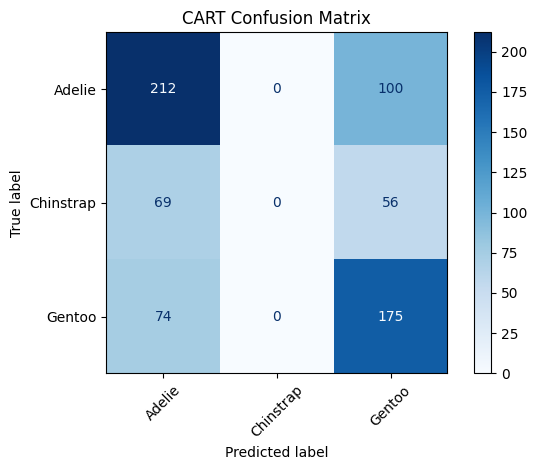


Classification Report:
              precision    recall  f1-score   support

      Adelie       0.60      0.68      0.64       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.53      0.70      0.60       249

    accuracy                           0.56       686
   macro avg       0.38      0.46      0.41       686
weighted avg       0.46      0.56      0.51       686



In [ ]:

# Task 5: Evaluate CART Model

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Calculate accuracy
cart_accuracy = accuracy_score(y_test, y_pred_cart)
print("CART Classification Accuracy:",
      round(cart_accuracy, 4))

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_cart)

print("\nConfusion Matrix:")
print(cm)

# Display confusion matrix graph
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
).plot(cmap="Blues", xticks_rotation=45)

plt.title("CART Confusion Matrix")
plt.tight_layout()
plt.show()

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_cart,
    target_names=encoder.classes_,
    zero_division=0
))


# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


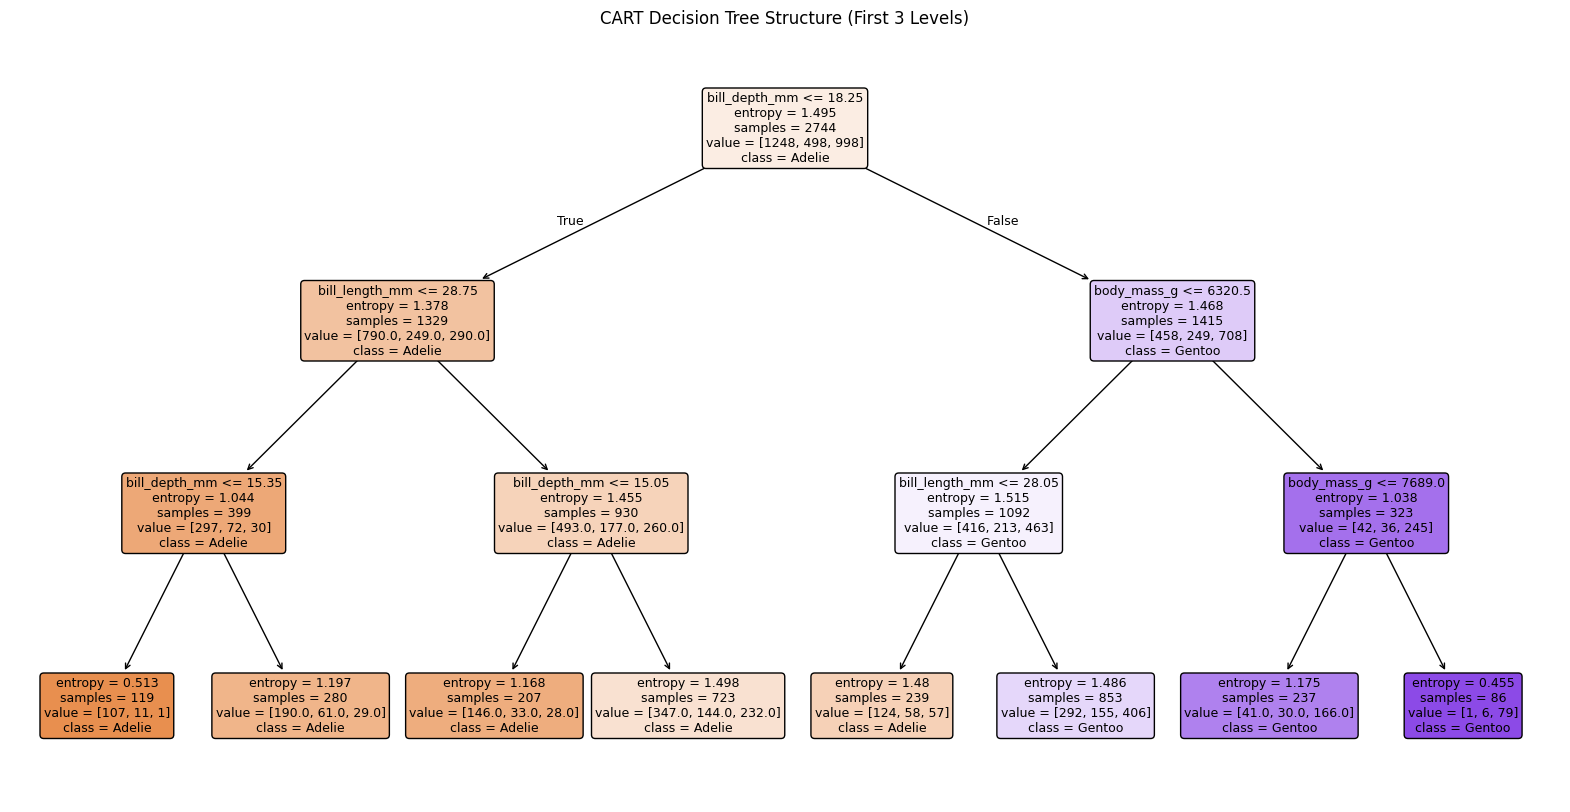

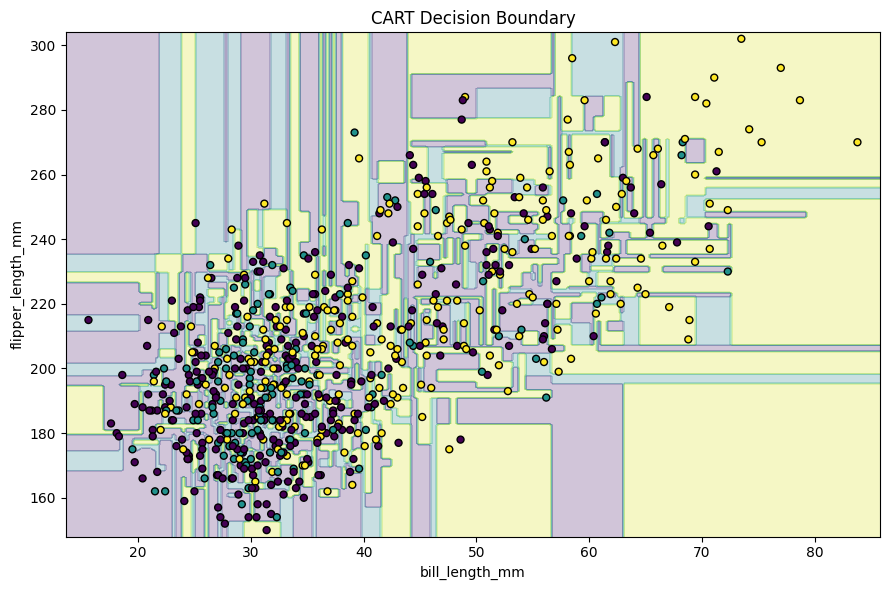

2D CART Accuracy: 0.4388


In [ ]:

# Task 6: Visualize the Decision Tree Structure

from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    cart_model,
    feature_names=features,
    class_names=encoder.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("CART Decision Tree Structure (First 3 Levels)")
plt.show()


# Train a Decision Tree using 2 features for visualization
features_2d = ["bill_length_mm", "flipper_length_mm"]

X_2d = data[features_2d]
y_2d = y

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d,
    y_2d,
    test_size=0.20,
    random_state=42,
    stratify=y_2d
)

tree_2d = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

tree_2d.fit(X2_train, y2_train)


# Function to plot decision boundaries
def plot_boundary(model, X, y, ax, title):
    x_min, x_max = X.iloc[:, 0].min() - 2, X.iloc[:, 0].max() + 2
    y_min, y_max = X.iloc[:, 1].min() - 2, X.iloc[:, 1].max() + 2

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = pd.DataFrame(
        np.c_[xx.ravel(), yy.ravel()],
        columns=X.columns
    )

    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, Z,
        alpha=0.25,
        cmap="viridis"
    )

    ax.scatter(
        X.iloc[:, 0],
        X.iloc[:, 1],
        c=y,
        cmap="viridis",
        edgecolors="black",
        s=25
    )

    ax.set_xlabel(X.columns[0])
    ax.set_ylabel(X.columns[1])
    ax.set_title(title)


fig, ax = plt.subplots(figsize=(9, 6))

plot_boundary(
    tree_2d,
    X2_test,
    y2_test,
    ax,
    "CART Decision Boundary"
)

plt.tight_layout()
plt.show()

print("2D CART Accuracy:",
      round(accuracy_score(y2_test, tree_2d.predict(X2_test)), 4))


# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

Logistic Regression trained successfully.
2D Logistic Regression Accuracy: 0.5262


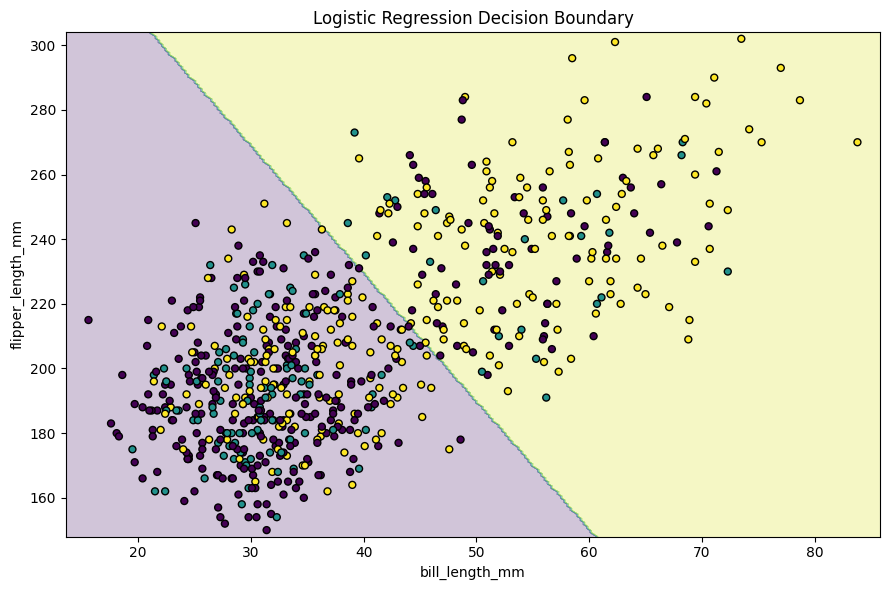

In [ ]:

# Task 7: Logistic Regression using 2 features

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logistic_2d = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

logistic_2d.fit(X2_train, y2_train)

y2_pred_logistic = logistic_2d.predict(X2_test)

print("Logistic Regression trained successfully.")
print("2D Logistic Regression Accuracy:",
      round(accuracy_score(y2_test, y2_pred_logistic), 4))

# Plot the linear classifier boundary
fig, ax = plt.subplots(figsize=(9, 6))

plot_boundary(
    logistic_2d,
    X2_test,
    y2_test,
    ax,
    "Logistic Regression Decision Boundary"
)

plt.tight_layout()
plt.show()


# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

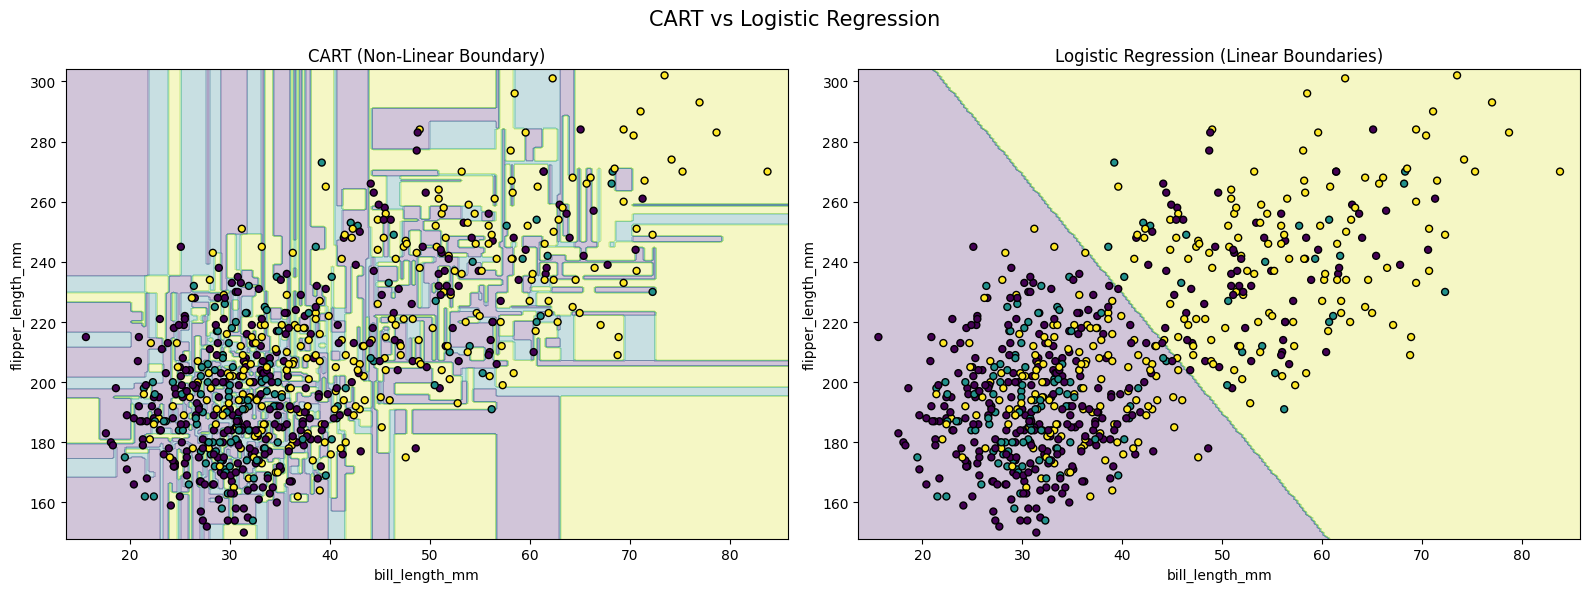

In [ ]:

# Task 8: Side-by-Side Decision Boundary Comparison

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_boundary(
    tree_2d,
    X2_test,
    y2_test,
    axes[0],
    "CART (Non-Linear Boundary)"
)

plot_boundary(
    logistic_2d,
    X2_test,
    y2_test,
    axes[1],
    "Logistic Regression (Linear Boundaries)"
)

plt.suptitle("CART vs Logistic Regression", fontsize=15)
plt.tight_layout()
plt.show()


# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

========== MODEL COMPARISON ==========

CART Accuracy: 0.5641
Logistic Regression Accuracy: 0.5787

========== CART CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      Adelie       0.60      0.68      0.64       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.53      0.70      0.60       249

    accuracy                           0.56       686
   macro avg       0.38      0.46      0.41       686
weighted avg       0.46      0.56      0.51       686


===== LOGISTIC REGRESSION CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

      Adelie       0.57      0.77      0.66       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.59      0.63      0.61       249

    accuracy                           0.58       686
   macro avg       0.39      0.47      0.42       686
weighted avg       0.47      0.58      0.52       686



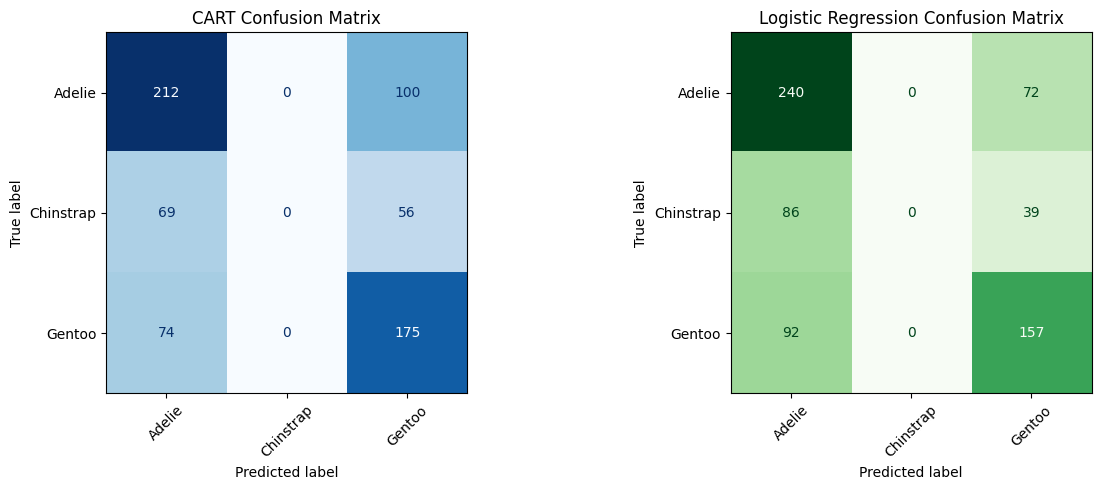

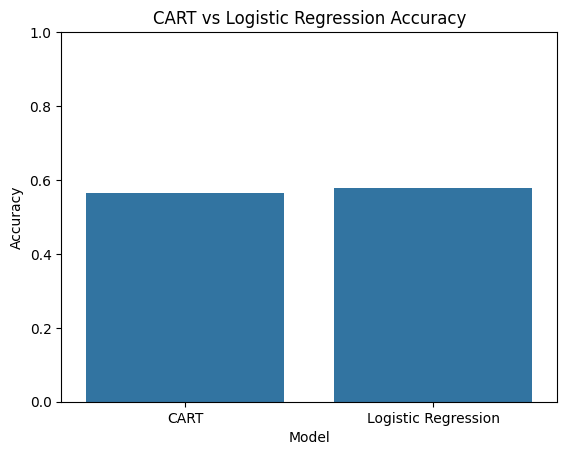

In [ ]:

# Task 9: Compare CART and Logistic Regression Performance

# Train Logistic Regression using all 4 features
logistic_full = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

logistic_full.fit(X_train, y_train)

# Predictions
y_pred_cart = cart_model.predict(X_test)
y_pred_logistic = logistic_full.predict(X_test)

# Calculate accuracy
cart_accuracy = accuracy_score(y_test, y_pred_cart)
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

print("========== MODEL COMPARISON ==========")

print("\nCART Accuracy:",
      round(cart_accuracy, 4))

print("Logistic Regression Accuracy:",
      round(logistic_accuracy, 4))


# Compare classification reports
print("\n========== CART CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test,
    y_pred_cart,
    target_names=encoder.classes_,
    zero_division=0
))

print("\n===== LOGISTIC REGRESSION CLASSIFICATION REPORT =====")

print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=encoder.classes_,
    zero_division=0
))


# Display confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, y_pred_cart),
    display_labels=encoder.classes_
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("CART Confusion Matrix")
axes[0].tick_params(axis="x", rotation=45)

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, y_pred_logistic),
    display_labels=encoder.classes_
).plot(ax=axes[1], cmap="Greens", colorbar=False)

axes[1].set_title("Logistic Regression Confusion Matrix")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


# Accuracy comparison chart
comparison = pd.DataFrame({
    "Model": ["CART", "Logistic Regression"],
    "Accuracy": [cart_accuracy, logistic_accuracy]
})

sns.barplot(data=comparison, x="Model", y="Accuracy")
plt.title("CART vs Logistic Regression Accuracy")
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.show()


# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.